# 2. Next-season production model

Goal: predict a player's next-season PPR points. Evaluation is **walk-forward**: for each test season the model trains only on earlier seasons, then is scored on players it has never seen. Baselines: *persistence* (next year = this year) and *age curve* (this year x position/age retention).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from datascience.features import *
from datascience.model import *
from datascience.collect import load_snapshots, load_trades
table = season_features()
curves = aging_curves(table)
folds = walk_forward(table, curves)
folds.round(2)

,mae,rmse,spearman,season,method,n,band_coverage
0,44.37,63.53,0.64,2018,model,470,0.77
1,49.33,70.41,0.63,2018,persistence,470,NaN
2,47.62,68.43,0.64,2018,age_curve,470,NaN
3,43.84,60.02,0.70,2019,model,455,0.75
4,48.87,69.06,0.67,2019,persistence,455,NaN
5,47.44,67.26,0.68,2019,age_curve,455,NaN
6,44.06,62.25,0.69,2020,model,488,0.77
7,48.44,68.84,0.67,2020,persistence,488,NaN
8,46.63,67.04,0.68,2020,age_curve,488,NaN
9,40.43,56.71,0.71,2021,model,500,0.78


In [2]:
summary = summarize_walk_forward(folds)
pd.DataFrame(summary).T

,mae,rmse,spearman,folds,band_coverage
age_curve,45.51,65.36,0.693,7.0,NaN
model,42.22,59.50,0.708,7.0,0.774
persistence,47.05,67.27,0.684,7.0,NaN


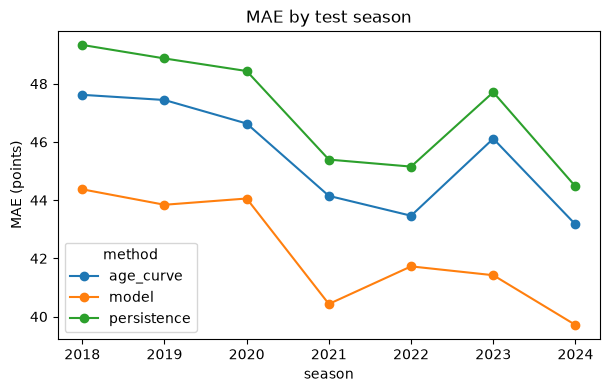

In [3]:
pivot = folds.pivot(index='season', columns='method', values='mae')
pivot.plot(marker='o', figsize=(7, 4), title='MAE by test season'); plt.ylabel('MAE (points)'); plt.show()

## Reading the result
The model beats both baselines on every fold, but only modestly (roughly 10% lower MAE than persistence). Next-season football production is mostly noise: injuries, role changes, and team context are not in the features. The 20-80% quantile band should contain roughly 60% of outcomes if calibrated; `band_coverage` reports the realised share.

In [4]:
usable = training_frame(table)
model = fit_production_model(usable[usable.season < usable.season.max()])
test = usable[usable.season == usable.season.max()]
pred = model.predict(test)
res = test[['name','position','points','next_points']].join(pred)
res['err'] = res.pred_points - res.next_points
res.sort_values('next_points', ascending=False).head(10).round(1)

,name,position,points,next_points,pred_points,pred_low,pred_high,err
4616,Christian McCaffrey,RB,47.8,416.6,114.9,0.0,198.2,-301.7
7761,Puka Nacua,WR,206.6,375.0,240.3,0.0,320.6,-134.7
7552,Bijan Robinson,RB,341.7,370.8,222.1,0.0,329.1,-148.7
7765,Jahmyr Gibbs,RB,362.9,366.9,241.6,0.0,326.7,-125.3
5801,Josh Allen,QB,379.0,364.6,287.0,249.7,345.8,-77.6
6519,Jonathan Taylor,RB,244.7,362.3,201.4,0.0,275.9,-160.9
7555,Jaxon Smith-Njigba,WR,253.0,359.9,215.4,0.0,243.2,-144.5
7913,Drake Maye,QB,177.1,352.0,193.1,54.8,257.5,-158.8
827,Matthew Stafford,QB,214.6,350.4,159.9,44.8,227.6,-190.5
7083,Trevor Lawrence,QB,145.2,338.2,179.8,15.2,264.9,-158.4


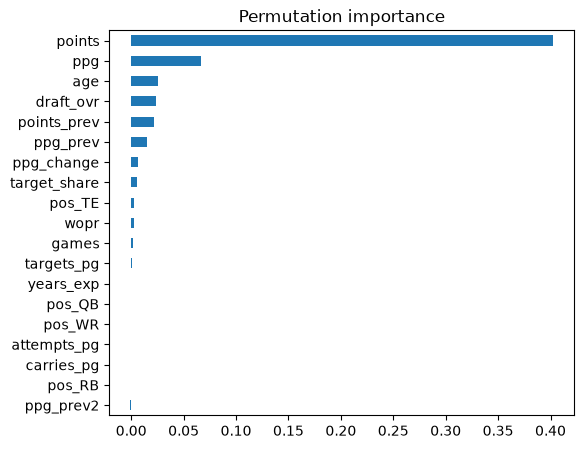

In [5]:
from sklearn.inspection import permutation_importance
x = feature_matrix(test); y = test.next_points.to_numpy()
imp = permutation_importance(model.mean, x, y, n_repeats=5, random_state=0)
pd.Series(imp.importances_mean, index=FEATURE_COLUMNS).sort_values().plot.barh(figsize=(6, 5), title='Permutation importance'); plt.show()